True: avg degree = 20.0066 prop > 10 = 0.98935
uniform bias = [0.0177     0.00018333] SE = [0.23887987 0.00606771]
random_walk bias = [0.9985     0.00628333] SE = [0.2728243  0.00436019]
metropolis bias = [0.0037525 0.000302 ] SE = [0.04625532 0.0016202 ]


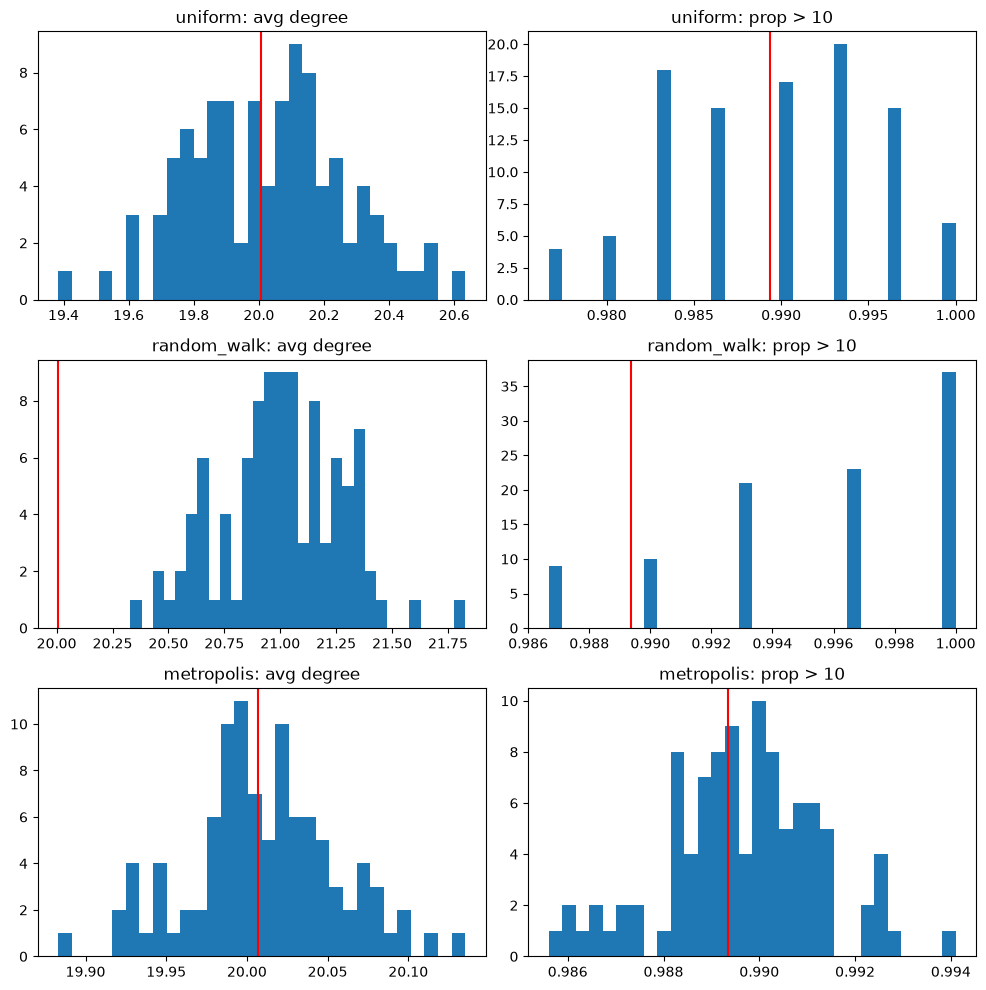

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
N, p = 20000, 0.001
g = nx.fast_gnp_random_graph(N, p, seed=0)
deg = np.array([d for _, d in g.degree()])
nbrs = [list(g.neighbors(v)) for v in range(N)]
theta = np.array([deg.mean(), np.mean(deg > 10)])

n, n_steps, reps = 300, 20000, 100

def est(Y):
    return deg[Y].mean(), np.mean(deg[Y] > 10)

def uniform():
    return est(rng.integers(N, size=n))

def random_walk():
    Y = [rng.integers(N)]
    for i in range(n - 1):
        Y.append(rng.choice(nbrs[Y[-1]]))
    return est(Y)

def metropolis():
    Y = [rng.integers(N)]
    for i in range(n_steps - 1):
        j = Y[-1]
        k = rng.choice(nbrs[j])
        alpha = min(deg[j] / deg[k], 1)
        Y.append(k if rng.random() < alpha else j)
    return est(Y)

print("True: avg degree =", theta[0], "prop > 10 =", theta[1])
fig, ax = plt.subplots(3, 2, figsize=(10, 10))

for i, f in enumerate([uniform, random_walk, metropolis]):
    res = np.array([f() for _ in range(reps)])
    print(f.__name__, "bias =", res.mean(axis=0) - theta, "SE =", res.std(axis=0, ddof=1))

    for c, name in enumerate(["avg degree", "prop > 10"]):
        ax[i, c].hist(res[:, c], bins=30)
        ax[i, c].axvline(theta[c], color="red")
        ax[i, c].set_title(f.__name__ + ": " + name)

plt.tight_layout()
plt.show()